<a href="https://colab.research.google.com/github/vincentmartin/tp-fine-tuning-student-version/blob/main/tp-fine-tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP fine-tuning de LLM avec LoRA

Dans le TP d'initiation, vous avez piloté un LLM uniquement par le **prompt**. Dans ce TP, vous allez modifier son **comportement** en l'entraînant sur vos propres données : c'est le *fine-tuning* supervisé (SFT, *Supervised Fine-Tuning*), réalisé avec la méthode **LoRA** sur le GPU gratuit de Colab.

En sortie de ce TP, vous serez capable de :
- Choisir entre prompt engineering, RAG et fine-tuning, et estimer la mémoire nécessaire à un entraînement
- Préparer un jeu de données d'instructions au format *prompt / completion* avec le *chat template* du modèle
- Expliquer le masquage de la perte (*loss masking*) : sur quels tokens le modèle apprend-il ?
- Configurer LoRA (rang, alpha, modules ciblés) et calculer le nombre de paramètres entraînés
- Entraîner avec la bibliothèque TRL (`SFTTrainer`) et lire une courbe de perte
- Évaluer rigoureusement le modèle fine-tuné face au modèle de base (ROUGE, exemples, oubli catastrophique)
- Sauvegarder, recharger et fusionner un adaptateur LoRA
- (Mini-projet) Appliquer QLoRA à un modèle plus gros, ou étudier l'effet de la quantité de données

**Modèle utilisé** : [Qwen3-1.7B](https://huggingface.co/Qwen/Qwen3-1.7B) (Apache 2.0), le même que dans le TP d'initiation. **Tâche** : résumer des dialogues ([DialogSum](https://huggingface.co/datasets/knkarthick/dialogsum)) dans le style des résumés humains du jeu de données.

### Instructions pour l'exécution sur Google Colab

Aller dans `Exécution -> Modifier le type d'exécution` puis sélectionner `T4 GPU`.

![Colab GPU](https://raw.githubusercontent.com/vincentmartin/tp-fine-tuning-student-version/main/resources/colab_gpu.png "T4-GPU")

**Pas de GPU disponible sur Colab ?** (quota atteint, heure de pointe) : utilisez [Kaggle Notebooks](https://www.kaggle.com/code), gratuit avec environ 30 h de GPU par semaine (`Settings -> Accelerator -> GPU T4 x2`, et activer `Internet` après vérification du compte par téléphone). Importez ce notebook via `File -> Import Notebook`.

**Durée des calculs** : l'entraînement principal prend une dizaine de minutes sur un T4. Pendant qu'il tourne, avancez sur les questions. Colab coupe une session inactive : gardez l'onglet ouvert.

**Assistants IA** : vous pouvez utiliser l'assistant intégré à Colab, mais vous devez être capables d'expliquer **chaque ligne** du code que vous rendez. Les questions d'analyse comptent autant que le code.

**Indices** : les exercices et les questions sont suivis d'indices repliables (💡, cliquez pour les ouvrir). Cherchez d'abord par vous-mêmes, puis ouvrez-les **un par un** : ils vont de la simple piste au squelette de code.

## 0. Installation et configuration

Colab fournit déjà `torch` : **ne le réinstallez pas**, cela casserait la compatibilité avec CUDA. Nous installons ou mettons à jour :
- **transformers**, **accelerate**, **datasets** : modèles, placement sur GPU, jeux de données
- **peft** : *Parameter-Efficient Fine-Tuning*, dont LoRA
- **trl** : *Transformer Reinforcement Learning*, la bibliothèque d'entraînement de Hugging Face (SFT, DPO, GRPO...)
- **bitsandbytes** : quantification 4 bits (QLoRA, mini-projet A)
- **evaluate** / **rouge_score** : métriques d'évaluation

In [2]:
%pip install -q -U transformers accelerate datasets peft trl bitsandbytes evaluate rouge_score
# Colab préinstalle une version de torchao trop ancienne pour peft (>= 0.16 requise) ; inutile ici, on la retire.
%pip uninstall -q -y torchao

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


**Remarque** : si l'import ci-dessous échoue juste après l'installation, redémarrez la session (`Exécution -> Redémarrer la session`) puis relancez les cellules à partir d'ici.

In [3]:
import gc
import os
import time

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import peft
import torch
import transformers
import trl
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed

print(f"torch {torch.__version__} | transformers {transformers.__version__} | peft {peft.__version__} | trl {trl.__version__}")

assert torch.cuda.is_available(), "Pas de GPU : vérifiez le type d'exécution (T4 GPU). Le fine-tuning sur CPU est inenvisageable."
print("GPU :", torch.cuda.get_device_name(0))
# Le T4 (architecture Turing, compute capability 7.5) ne gère pas nativement le bfloat16 :
# on utilise float16 sur ce type de GPU, bfloat16 sur les GPU récents (Ampere et +).
USE_BF16 = torch.cuda.get_device_capability()[0] >= 8
DTYPE = torch.bfloat16 if USE_BF16 else torch.float16


def gpu_memory():
    """Mémoire GPU actuellement allouée et pic depuis le dernier reset, en Go."""
    return f"{torch.cuda.memory_allocated() / 1e9:.2f} Go alloués (pic : {torch.cuda.max_memory_allocated() / 1e9:.2f} Go)"


def free_memory():
    """Libère la mémoire GPU des objets Python supprimés (à appeler après `del model`)."""
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()


set_seed(42)

torch 2.14.1+cu130 | transformers 5.23.0 | peft 0.22.0 | trl 1.18.2
GPU : Tesla T4


## 1. Pourquoi (et quand) fine-tuner ?

Pour adapter un LLM à un besoin, il existe trois leviers, du moins coûteux au plus coûteux :

| Levier | Ce qu'il change | Quand l'utiliser |
|---|---|---|
| **Prompt engineering** (TP d'initiation) | Les instructions et exemples donnés au modèle | Toujours en premier : rapide, gratuit, réversible |
| **RAG** | Les **connaissances** fournies dans le contexte | Le modèle doit répondre à partir de documents (internes, récents) |
| **Fine-tuning** | Les **poids** du modèle, donc son **comportement** | Un style, un format ou une tâche précise à reproduire de façon fiable, un prompt trop long à répéter, un petit modèle à rendre aussi bon qu'un gros sur **une** tâche |

Le fine-tuning est un mauvais outil pour ajouter des connaissances (le modèle hallucine sur ce qu'il a vu une seule fois) : pour cela, on préfère le RAG.

### Fine-tuning complet ou PEFT ?

Entraîner **tous** les poids d'un modèle (*full fine-tuning*) demande beaucoup de mémoire. Avec l'optimiseur Adam en précision mixte, il faut stocker pour **chaque paramètre** :
- les poids en 16 bits (2 octets) et leur gradient (2 octets) ;
- une copie des poids en 32 bits (4 octets) ;
- les deux moments d'Adam en 32 bits (2 × 4 octets).

Soit environ **16 octets par paramètre**, sans compter les activations.

**Exercice 1** : écrire la fonction `training_memory_gb(n_params, bytes_per_param)` et l'appliquer à Qwen3-1.7B (1,7 milliard de paramètres) et à un modèle de 8 milliards. Comparer à la mémoire d'un GPU T4 (15 Go).

<details>
<summary>💡 Indice 1 : la formule</summary>

Mémoire (octets) = nombre de paramètres × octets par paramètre. Il reste à convertir en Go : 1 Go = 10⁹ octets. La fonction tient en une ligne.

</details>

<details>
<summary>💡 Indice 2 : inférence ou entraînement</summary>

La boucle fournie appelle votre fonction deux fois : avec `bytes_per_param=2` (poids seuls en 16 bits, pour l'inférence) et avec la valeur par défaut de 16 (fine-tuning complet). Votre fonction doit donc utiliser son paramètre `bytes_per_param`, sans valeur codée en dur.

</details>

In [4]:
def training_memory_gb(n_params, bytes_per_param=16):
    return n_params * bytes_per_param / 1e9


for name, n_params in {"Qwen3-1.7B": 1.7e9, "Llama-3.1-8B": 8e9}.items():
    print(f"{name:12} : inférence fp16 ≈ {training_memory_gb(n_params, 2):5.1f} Go | fine-tuning complet ≈ {training_memory_gb(n_params):6.1f} Go")

Qwen3-1.7B   : inférence fp16 ≈   3.4 Go | fine-tuning complet ≈   27.2 Go
Llama-3.1-8B : inférence fp16 ≈  16.0 Go | fine-tuning complet ≈  128.0 Go


Le fine-tuning complet est donc hors de portée d'un T4, même pour un petit modèle. La solution est le **PEFT** (*Parameter-Efficient Fine-Tuning*) : on **gèle** les poids d'origine et on n'entraîne qu'un petit nombre de paramètres ajoutés. La méthode PEFT la plus utilisée est **LoRA** (*Low-Rank Adaptation*), que nous détaillons en partie 4.

**Question** : avec LoRA, seuls environ 1 % des paramètres sont entraînés. Que deviennent les 16 octets par paramètre pour les 99 % restants ? Quelle est alors, approximativement, la mémoire nécessaire pour Qwen3-1.7B ?

<details>
<summary>💡 Indice</summary>

Reprenez la liste des éléments stockés pour chaque paramètre : lesquels existent encore pour un paramètre **gelé**, qui ne reçoit pas de gradient et n'est donc pas mis à jour par Adam ? Faites ensuite deux calculs avec `training_memory_gb` : l'un pour les 99 % de poids gelés, l'autre pour les 1 % de paramètres entraînés.

</details>

✍️ **Votre réponse :**
Pour les 99 % de paramètres gelés, il ne reste que les poids en 16 bits (2 octets)

Pour Qwen3-1.7B :

poids gelés : 1,7 param x 2o ≈ 3,4 Go
paramètres LoRA : 0,017 param x 16o ≈ 0,27 Go

Total ≈ 3,6 Go contre 27,2 Go en fine-tuning complet. Cela tient dans la T4.


## 2. La tâche et le modèle de base

### Le jeu de données

[DialogSum](https://huggingface.co/datasets/knkarthick/dialogsum) contient environ 13 000 dialogues de la vie courante en anglais, chacun accompagné d'un résumé écrit par un humain. Les résumés suivent des **conventions précises** : les interlocuteurs sont désignés par `#Person1#` et `#Person2#`, le résumé tient en une ou deux phrases, au présent ou au passé.

In [5]:
dataset = load_dataset("knkarthick/dialogsum")
print(dataset)
example = dataset["train"][0]
print("\n--- DIALOGUE ---\n" + example["dialogue"])
print("\n--- RÉSUMÉ HUMAIN ---\n" + example["summary"])

README.md:   0%|          | 0.00/4.65k [00:00<?, ?B/s]

train.csv: reconstructing file:   0%|          |  0.00B / 11.3MB            

train.csv: downloading bytes:           |  0.00B            

validation.csv:   0%|          | 0.00/442k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/1.35M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/12460 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/500 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1500 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 12460
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 500
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 1500
    })
})

--- DIALOGUE ---
#Person1#: Hi, Mr. Smith. I'm Doctor Hawkins. Why are you here today?
#Person2#: I found it would be a good idea to get a check-up.
#Person1#: Yes, well, you haven't had one for 5 years. You should have one every year.
#Person2#: I know. I figure as long as there is nothing wrong, why go see the doctor?
#Person1#: Well, the best way to avoid serious illnesses is to find out about them early. So try to come at least once a year for your own good.
#Person2#: Ok.
#Person1#: Let me see here. Your eyes and ears look fine. Take a deep breath, please. Do you smoke, Mr. Smith?
#Person2#: Yes.
#Person1#: Smoking is the leading cause of

Pour l'évaluation, nous utilisons le split `test`. Attention : chaque dialogue de ce split y apparaît **3 fois**, avec 3 résumés humains différents. Nous regroupons donc les références par dialogue et évaluons sur des dialogues **distincts**, en comparant chaque prédiction aux 3 références (ROUGE prend alors le meilleur score).

In [6]:
N_EVAL = 50  # nombre de dialogues de test distincts utilisés pour l'évaluation

test_df = dataset["test"].to_pandas()
eval_df = test_df.groupby("dialogue", sort=False)["summary"].apply(list).reset_index().head(N_EVAL)
eval_dialogues = eval_df["dialogue"].tolist()
eval_references = eval_df["summary"].tolist()
print(f"{len(test_df)} lignes de test -> {test_df['dialogue'].nunique()} dialogues distincts, {len(eval_dialogues)} utilisés")

1500 lignes de test -> 500 dialogues distincts, 50 utilisés


### Le modèle de base

Nous chargeons Qwen3-1.7B en 16 bits. C'est un modèle *instruct* : il sait déjà résumer, sans aucun entraînement de notre part. La question est donc : **le fine-tuning apporte-t-il quelque chose par rapport à un bon modèle généraliste ?**

In [7]:
MODEL_NAME = "Qwen/Qwen3-1.7B"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=DTYPE, device_map="cuda")
print(f"{model.num_parameters() / 1e9:.2f} milliards de paramètres | {gpu_memory()}")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

1.72 milliards de paramètres | 3.44 Go alloués (pic : 4.37 Go)


Les deux fonctions ci-dessous sont fournies. `build_messages` construit la conversation envoyée au modèle ; `summarize` génère les résumés **par lots** (*batch*), ce qui est bien plus rapide qu'un dialogue à la fois.

Notez deux détails importants pour un modèle *decoder-only* :
- le *padding* se fait **à gauche** pour la génération par lots, afin que tous les prompts se terminent au même endroit et que la génération démarre juste après ;
- on ne décode que les **nouveaux tokens**, sinon la sortie contient aussi le prompt (une erreur fréquente qui fausse complètement l'évaluation).

In [8]:
INSTRUCTION = "Summarize the following conversation."


def build_messages(dialogue):
    return [{"role": "user", "content": f"{INSTRUCTION}\n\n{dialogue}"}]


@torch.no_grad()
def summarize(model, dialogues, batch_size=16, max_new_tokens=128):
    """Résume une liste de dialogues en décodage glouton (greedy), sans mode raisonnement."""
    model.eval()
    tokenizer.padding_side = "left"
    summaries = []
    for start in range(0, len(dialogues), batch_size):
        prompts = [
            tokenizer.apply_chat_template(build_messages(d), tokenize=False, add_generation_prompt=True, enable_thinking=False)
            for d in dialogues[start:start + batch_size]
        ]
        inputs = tokenizer(prompts, return_tensors="pt", padding=True).to(model.device)
        outputs = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False, temperature=None, top_p=None, top_k=None)
        new_tokens = outputs[:, inputs["input_ids"].shape[1]:]
        summaries += [s.strip() for s in tokenizer.batch_decode(new_tokens, skip_special_tokens=True)]
    return summaries


print(summarize(model, [example["dialogue"]])[0])

The conversation is between Doctor Hawkins and Mr. Smith, who is visiting for a check-up. Mr. Smith has not had a check-up in five years and is unsure if he needs one. Doctor Hawkins advises him to get regular check-ups to catch illnesses early. Mr. Smith acknowledges the advice and mentions he smokes, which the doctor warns is a major risk factor for lung and heart disease. The doctor offers support through classes and medications to help him quit smoking. Mr. Smith agrees to follow up.


**Exercice 2** : générer les résumés du modèle de base sur les `N_EVAL`

dialogues d'évaluation (variable `base_summaries`), puis écrire la fonction `rouge_scores(predictions, references)` qui renvoie les scores ROUGE en pourcentage. Le module `evaluate` accepte plusieurs références par prédiction (une liste de listes).

<details>
<summary>💡 Indice 1 : générer</summary>

Pas besoin de réécrire la génération : la fonction `summarize` est fournie. Appelez-la avec le modèle et la liste `eval_dialogues`. Comptez une à deux minutes sur un T4.

</details>

<details>
<summary>💡 Indice 2 : calculer ROUGE</summary>

`rouge.compute(predictions=..., references=..., use_stemmer=True)` renvoie un dictionnaire de scores entre 0 et 1 (`rouge1`, `rouge2`, `rougeL`, `rougeLsum`). Une compréhension de dictionnaire suffit pour les multiplier par 100 et les arrondir.

</details>

In [9]:
rouge = evaluate.load("rouge")


def rouge_scores(predictions, references):
    result={}
    dico_scores = rouge.compute(predictions=predictions, references=references, use_stemmer=True)
    print("ok")
    for k, v in dico_scores.items():
      result[k] = round(v * 100, 2)
    return result




start = time.time()
base_summaries = summarize(model, eval_dialogues)
# VOTRE CODE ICI
print(f"Génération : {time.time() - start:.0f} s")
base_scores = rouge_scores(base_summaries, eval_references)
base_scores

Génération : 68 s
ok


{'rouge1': np.float64(25.86),
 'rouge2': np.float64(8.87),
 'rougeL': np.float64(18.85),
 'rougeLsum': np.float64(18.88)}

**Exercice 3** : comparer la **longueur moyenne** (en mots) des résumés du modèle de base et des résumés humains, et afficher trois exemples côte à côte (dialogue tronqué, résumé humain, résumé du modèle).

<details>
<summary>💡 Indice 1 : les références</summary>

La fonction `mean_words` est fournie. Attention : `eval_references` est une liste de **listes** (3 résumés humains par dialogue). Pour la longueur et l'affichage, prenez par exemple la première référence de chaque dialogue.

</details>

<details>
<summary>💡 Indice 2 : l'affichage côte à côte</summary>

Un `pd.DataFrame` avec trois colonnes (dialogue tronqué à 200 caractères avec `d[:200]`, résumé humain, résumé du modèle) restreint aux trois premiers exemples. `pd.set_option("display.max_colwidth", 300)` évite que pandas coupe les textes.

</details>

In [10]:
def mean_words(texts):
    return np.mean([len(t.split()) for t in texts])

print("nbr de mots du résumés")
print("modele")
print(mean_words(base_summaries))
print("humain")
print(mean_words(eval_references[0]))
# VOTRE CODE ICI

for i in range(3):
    print(f"\n=== Exemple {i} ===")
    print("DIALOGUE  :", eval_dialogues[i][:300] + "...")
    print("HUMAIN    :", eval_references[0][i])
    print("MODÈLE    :", base_summaries[i])

nbr de mots du résumés
modele
76.7
humain
30.0

=== Exemple 0 ===
DIALOGUE  : #Person1#: Ms. Dawson, I need you to take a dictation for me.
#Person2#: Yes, sir...
#Person1#: This should go out as an intra-office memorandum to all employees by this afternoon. Are you ready?
#Person2#: Yes, sir. Go ahead.
#Person1#: Attention all staff... Effective immediately, all office commu...
HUMAIN    : Ms. Dawson helps #Person1# to write a memo to inform every employee that they have to change the communication method and should not use Instant Messaging anymore.
MODÈLE    : The conversation involves a manager, Ms. Dawson, who informs her staff about a new policy restricting all office communications to email and official memos, prohibiting the use of Instant Messaging during work hours. The policy applies to both internal and external communications. Employees are warned that repeated violations may result in warnings, probation, or termination. The memo must be distributed by 4 pm.

=== Exemple 

**Question** : quelles différences de **forme** observez-vous entre les résumés du modèle et ceux des humains ? Pourquoi pénalisent-elles le score ROUGE, alors que le résumé du modèle est peut-être correct ? Pourriez-vous les corriger par le prompt seul (pensez au few-shot du TP d'initiation) ? À quel prix ?

<details>
<summary>💡 Indice</summary>

Regardez le **début** des résumés du modèle (formule d'introduction ?), la façon de **nommer les interlocuteurs** et la **longueur** mesurée à l'exercice 3. Rappelez-vous que ROUGE compte les mots et n-grammes communs avec la référence : que deviennent la précision et le score quand le résumé contient beaucoup de mots absents des références ? Pour le prix du few-shot, pensez au nombre de tokens ajoutés à **chaque** requête.

</details>

✍️ **Votre réponse :**
Le résumé humain est bcp plus bref que le résumé du modèle, elle pénalise le score car il ce base sur la similarité des mots et leur présence sachant qu'elle plus est cours donc la similiraté peut etre que faible. Ou en prenant les 3 exemple humain au dessus et en disant qu'on veut des résumé similaires, le prix risque d'etre des prompt moins pertinent


## 3. Préparer les données

### Le format *prompt / completion*

Pour l'entraînement, chaque exemple est découpé en deux parties :
- **prompt** : ce que le modèle reçoit, exactement comme à l'inférence (chat template compris) ;
- **completion** : ce que le modèle doit apprendre à produire, ici le résumé humain.

C'est le format attendu par le `SFTTrainer` de TRL. Point essentiel : le prompt d'entraînement doit être **identique** à celui utilisé à l'inférence (même instruction, même chat template, même gestion du mode raisonnement), sinon le modèle n'appliquera pas ce qu'il a appris.

**Exercice 4** : écrire `format_example(example)` qui renvoie un dictionnaire `{"prompt": ..., "completion": ...}`. Le prompt est le texte produit par le chat template à partir de `build_messages`, avec `add_generation_prompt=True` et `enable_thinking=False` (comme dans `summarize`). La completion est le résumé humain.

<details>
<summary>💡 Indice 1 : le prompt</summary>

Le prompt doit être identique à celui de l'inférence : reprenez l'appel à `tokenizer.apply_chat_template` de la fonction `summarize`, avec les mêmes arguments, appliqué à `build_messages(example["dialogue"])`.

</details>

<details>
<summary>💡 Indice 2 : le résultat</summary>

`tokenize=False` renvoie du texte (et non des ids). La completion est simplement `example["summary"]`. La fonction renvoie un dictionnaire à deux clés : c'est ce qui permet de l'utiliser avec `dataset.map(format_example)`.

</details>

In [11]:
def format_example(example):
    #print(example)
    # VOTRE CODE ICI
    prompt = tokenizer.apply_chat_template(
        build_messages(example["dialogue"]),
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,
    )
    return {"prompt":prompt,"completion":example["summary"]}


formatted = format_example(dataset["train"][0])
print(formatted["prompt"] + formatted["completion"])

<|im_start|>user
Summarize the following conversation.

#Person1#: Hi, Mr. Smith. I'm Doctor Hawkins. Why are you here today?
#Person2#: I found it would be a good idea to get a check-up.
#Person1#: Yes, well, you haven't had one for 5 years. You should have one every year.
#Person2#: I know. I figure as long as there is nothing wrong, why go see the doctor?
#Person1#: Well, the best way to avoid serious illnesses is to find out about them early. So try to come at least once a year for your own good.
#Person2#: Ok.
#Person1#: Let me see here. Your eyes and ears look fine. Take a deep breath, please. Do you smoke, Mr. Smith?
#Person2#: Yes.
#Person1#: Smoking is the leading cause of lung cancer and heart disease, you know. You really should quit.
#Person2#: I've tried hundreds of times, but I just can't seem to kick the habit.
#Person1#: Well, we have classes and some medications that might help. I'll give you more information before you leave.
#Person2#: Ok, thanks doctor.<|im_end|>
<|

**Question** : le prompt se termine par `<think>\n\n</think>\n\n`. D'où vient ce bloc et pourquoi est-il important de le garder à l'entraînement ? Par quel token la séquence d'entraînement doit-elle se terminer, et que se passerait-il à l'inférence s'il était absent ?

<details>
<summary>💡 Indice</summary>

Affichez le prompt obtenu avec `enable_thinking=True`, puis avec `enable_thinking=False` : quelle est la différence ? Pour le token de fin, affichez `tokenizer.eos_token` et demandez-vous quand `model.generate` s'arrête de générer.

</details>

✍️ **Votre réponse :**

On foit que quand il est insert naturellement think vide pour pas que le model s'habitue qu'il soit toujours présent que ca ne change pas ca sortie. Il faut qu'il ce termine par <|im_end|> . il s'arreterais quand il attendrais la limite de max_new_tokens




### Longueur des exemples

Plus les séquences sont longues, plus l'entraînement consomme de mémoire (les activations sont proportionnelles à la longueur) et de temps. Les quelques exemples très longs déterminent souvent le pic de mémoire.

**Exercice 5** : calculer le nombre de tokens de chaque exemple d'entraînement (prompt + completion) sur les 2 000 premiers exemples, tracer l'histogramme et afficher les quantiles à 50 %, 95 % et 99 %. Choisir une valeur de `MAX_LENGTH` qui conserve environ 98 % des exemples.

<details>
<summary>💡 Indice 1 : compter les tokens</summary>

Pour chaque exemple, tokenisez `prompt + completion` avec `add_special_tokens=False` et prenez la longueur de `input_ids`. Une compréhension de liste sur `zip(sample["prompt"], sample["completion"])`, convertie en `np.array`, suffit (quelques secondes).

</details>

<details>
<summary>💡 Indice 2 : quantiles et histogramme</summary>

`np.percentile(lengths, [50, 95, 99])` donne les quantiles, `plt.hist(lengths, bins=50)` l'histogramme. Pour garder 98 % des exemples, regardez `np.percentile(lengths, 98)` et arrondissez à une valeur ronde au-dessus.

</details>

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

303


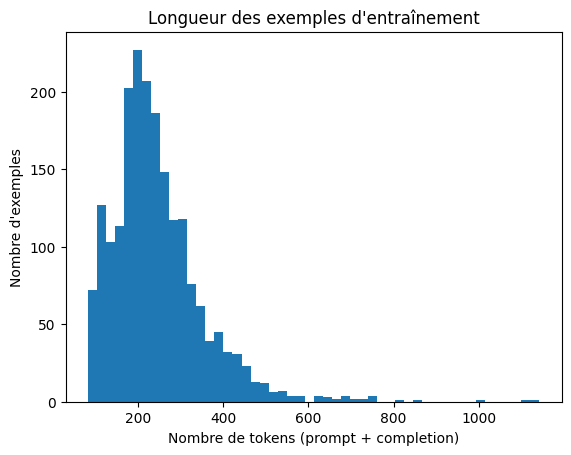

Quantile 50% : 226 tokens
Quantile 95% : 440 tokens
Quantile 98% : 529 tokens
Quantile 99% : 644 tokens


In [12]:
sample = dataset["train"].select(range(2000)).map(format_example)
# VOTRE CODE ICI
#test avec le premier exemple

ex = sample[0] # choix de lexemple 0
n_tokens = len(tokenizer(ex["prompt"] + ex["completion"], add_special_tokens=False)["input_ids"])
print(n_tokens)


lengths = [
    len(tokenizer(ex["prompt"] + ex["completion"], add_special_tokens=False)["input_ids"])
    for ex in sample
]

plt.hist(lengths, bins=50)
plt.xlabel("Nombre de tokens (prompt + completion)")
plt.ylabel("Nombre d'exemples")
plt.title("Longueur des exemples d'entraînement")
plt.show()

for q in (0.50, 0.95, 0.98, 0.99):
    print(f"Quantile {q:.0%} : {np.quantile(lengths, q):.0f} tokens")

In [13]:
MAX_LENGTH = 800  # à ajuster selon votre analyse

Plutôt que de **tronquer** les exemples trop longs (ce qui couperait la fin, c'est-à-dire... le résumé à apprendre !), nous les **retirons**. Nous prenons 1 000 exemples d'entraînement et 100 de validation : c'est peu, mais suffisant pour apprendre un style, et l'entraînement reste d'une dizaine de minutes sur un T4.

In [14]:
N_TRAIN, N_VALID = 1000, 100


def prepare(split, n):
    ds = dataset[split].shuffle(seed=42).select(range(3 * n)).map(format_example)
    ds = ds.filter(lambda ex: len(tokenizer(ex["prompt"] + ex["completion"], add_special_tokens=False)["input_ids"]) < MAX_LENGTH)
    return ds.select(range(n)).select_columns(["prompt", "completion"])


train_ds = prepare("train", N_TRAIN)
valid_ds = prepare("validation", N_VALID)
train_ds, valid_ds

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/3000 [00:00<?, ? examples/s]

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

Filter:   0%|          | 0/300 [00:00<?, ? examples/s]

(Dataset({
     features: ['prompt', 'completion'],
     num_rows: 1000
 }),
 Dataset({
     features: ['prompt', 'completion'],
     num_rows: 100
 }))

### Sur quels tokens le modèle apprend-il ?

Un LLM *decoder-only* est entraîné à **prédire le token suivant** : la perte (*cross-entropy*) est calculée à chaque position de la séquence. Pour le fine-tuning d'instructions, on ne veut **pas** que le modèle apprenne à générer le prompt (les dialogues) : on veut qu'il apprenne à produire la réponse **sachant** le prompt.

On fournit donc au modèle, pour chaque exemple :
- `input_ids` : les tokens du prompt suivis de ceux de la completion ;
- `labels` : une copie de `input_ids` où les positions du prompt sont remplacées par **-100**, la valeur que PyTorch ignore dans le calcul de la perte.

(Le décalage d'une position entre entrée et cible est fait automatiquement à l'intérieur du modèle.)

**Exercice 6** : écrire `build_labels(prompt, completion)` qui renvoie `input_ids` et `labels` pour un exemple, en ajoutant le token de fin `tokenizer.eos_token_id` à la fin de la completion. Vérifier en décodant uniquement les tokens dont le label n'est pas -100.

<details>
<summary>💡 Indice 1 : les ids</summary>

Tokenisez **séparément** le prompt et la completion (`add_special_tokens=False`), ajoutez `tokenizer.eos_token_id` à la fin des ids de la completion, puis concaténez les deux listes. Tokeniser séparément vous donne directement la frontière entre prompt et completion.

</details>

<details>
<summary>💡 Indice 2 : les labels</summary>

`labels` a la même longueur que `input_ids` : `[-100] * len(prompt_ids)` suivi des ids de la completion (fin comprise). Ne décalez pas les labels d'une position : le modèle le fait lui-même.

</details>

In [15]:
def build_labels(prompt, completion):
    prompt_ids = tokenizer(prompt, add_special_tokens=False)["input_ids"]
    completion_ids = tokenizer(completion, add_special_tokens=False)["input_ids"] + [tokenizer.eos_token_id]
    input_ids = prompt_ids + completion_ids
    labels = [-100] * len(prompt_ids) + completion_ids
    return input_ids, labels


input_ids, labels = build_labels(train_ds[0]["prompt"], train_ds[0]["completion"])
print(f"{len(input_ids)} tokens, dont {sum(l != -100 for l in labels)} comptent dans la perte")
print(repr(tokenizer.decode([l for l in labels if l != -100])))

379 tokens, dont 42 comptent dans la perte
"Jason hasn't called Anna for a long time. He calls her to tell her he got a promotion and he feels good about it. Anna invites him to come over to her house tonight to get drunk.<|im_end|>"


**Question** : sur cet exemple, quelle proportion des tokens contribue à la perte ? Que se passerait-il si l'on calculait la perte sur toute la séquence (prompt compris) ? Et si l'on oubliait les -100 sur les tokens de *padding* ajoutés pour former des lots de même longueur ?

<details>
<summary>💡 Indice</summary>

La cellule précédente affiche le nombre total de tokens et ceux qui comptent dans la perte. Sans masquage : sur quelle partie de la séquence porterait l'essentiel du signal d'apprentissage, et qu'apprendrait donc surtout le modèle ? Pour le padding, affichez `tokenizer.pad_token` : à quel token ressemble-t-il ?

</details>

✍️ **Votre réponse :**
Environ 10 pourcents.
Il apprendrais a générer aussi des prompts pas seulement a répondre.
si on laisse le padding il risque d'apprendre des bias ou meme a généré du padding


## 4. LoRA : *Low-Rank Adaptation*

LoRA gèle chaque matrice de poids $W$ (de taille $d_{out} \times d_{in}$) du modèle et lui ajoute une mise à jour de **rang faible** :

$$W' = W + \frac{\alpha}{r} B A \qquad A \in \mathbb{R}^{r \times d_{in}},\; B \in \mathbb{R}^{d_{out} \times r}$$

Seules $A$ et $B$ sont entraînées. $B$ est initialisée à zéro : au début de l'entraînement, le modèle est **exactement** le modèle d'origine. Les hyperparamètres principaux :
- **`r`** (rang) : la capacité de l'adaptateur. 8 à 32 suffisent pour apprendre un style ou une tâche ;
- **`lora_alpha`** : un facteur d'échelle, souvent fixé à `r` ou `2 * r` ;
- **`target_modules`** : les matrices adaptées. Les études récentes montrent qu'adapter **toutes** les couches linéaires (`"all-linear"` : attention et MLP) donne de meilleurs résultats qu'adapter seulement `q` et `v` comme dans l'article LoRA d'origine (2021).

À la fin, l'adaptateur ne pèse que quelques dizaines de Mo, et on peut en entraîner un par tâche sur le même modèle de base.

In [16]:
from peft import LoraConfig, get_peft_model

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules="all-linear",
    task_type="CAUSAL_LM",
)

**Exercice 7** : calculer **à la main** le nombre de paramètres LoRA ajoutés. Pour une couche linéaire $d_{in} \to d_{out}$, LoRA ajoute $r \times (d_{in} + d_{out})$ paramètres. Les dimensions de chaque couche linéaire d'un bloc sont données par `model.model.layers[0]`, et le nombre de blocs par `model.config.num_hidden_layers`.

<details>
<summary>💡 Indice 1 : lire l'architecture</summary>

Dans l'affichage de `model.model.layers[0]`, chaque `Linear` indique `in_features` et `out_features`. Avec `target_modules="all-linear"`, **toutes** les couches linéaires du bloc sont adaptées : celles de l'attention (`q_proj`, `k_proj`, `v_proj`, `o_proj`) et celles du MLP (`gate_proj`, `up_proj`, `down_proj`).

</details>

<details>
<summary>💡 Indice 2 : en code</summary>

`block.modules()` parcourt tous les sous-modules d'un bloc ; filtrez ceux pour lesquels `isinstance(m, torch.nn.Linear)` est vrai. Sommez `lora_config.r * (m.in_features + m.out_features)`, puis multipliez par `model.config.num_hidden_layers` (tous les blocs sont identiques).

</details>

In [17]:
print(model.model.layers[0])

Qwen3DecoderLayer(
  (self_attn): Qwen3Attention(
    (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
    (k_proj): Linear(in_features=2048, out_features=1024, bias=False)
    (v_proj): Linear(in_features=2048, out_features=1024, bias=False)
    (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
    (q_norm): Qwen3RMSNorm((128,), eps=1e-06)
    (k_norm): Qwen3RMSNorm((128,), eps=1e-06)
  )
  (mlp): Qwen3MLP(
    (gate_proj): Linear(in_features=2048, out_features=6144, bias=False)
    (up_proj): Linear(in_features=2048, out_features=6144, bias=False)
    (down_proj): Linear(in_features=6144, out_features=2048, bias=False)
    (act_fn): SiLUActivation()
  )
  (input_layernorm): Qwen3RMSNorm((2048,), eps=1e-06)
  (post_attention_layernorm): Qwen3RMSNorm((2048,), eps=1e-06)
)


In [18]:
# VOTRE CODE ICI
#Pour chaque couche, on calcule r × (d_in + d_out)
layers = {
    "q_proj":    (2048, 2048),
    "k_proj":    (2048, 1024),
    "v_proj":    (2048, 1024),
    "o_proj":    (2048, 2048),
    "gate_proj": (2048, 6144),
    "up_proj":   (2048, 6144),
    "down_proj": (6144, 2048),
}
r=16 # choix d'un r

per_block = sum(r * (d_in + d_out) for d_in, d_out in layers.values())
expected = per_block * model.config.num_hidden_layers
print(f"Paramètres LoRA attendus : {expected:,}")

Paramètres LoRA attendus : 17,432,576


Ajoutons maintenant l'adaptateur au modèle et vérifions votre calcul.

**Attention** : `get_peft_model` **modifie le modèle en place** (les couches LoRA sont injectées dans `model`). Il n'existe donc plus de « modèle d'origine » séparé en mémoire : pour retrouver le comportement du modèle de base, on désactive temporairement l'adaptateur avec `with peft_model.disable_adapter():`. Comparer « le modèle d'origine » et « le modèle fine-tuné » sans en tenir compte est une erreur classique, qui figurait d'ailleurs dans l'ancienne version de ce TP.

In [19]:
peft_model = get_peft_model(model, lora_config)
peft_model.print_trainable_parameters()

trainable params: 17,432,576 || all params: 1,738,007,552 || trainable%: 1.0030


**Question** : quel pourcentage des paramètres est entraîné ? Combien de Mo pèsera l'adaptateur sauvegardé en 16 bits ? Comment évolue le nombre de paramètres si l'on double `r` ?

<details>
<summary>💡 Indice</summary>

`print_trainable_parameters` affiche directement le pourcentage. Pour la taille : nombre de paramètres × 2 octets, avec 1 Mo = 10⁶ octets (comparez à la taille réelle des fichiers en partie 7). Pour `r`, relisez la formule de l'exercice 7 : comment dépend-elle de `r` ?

</details>

✍️ **Votre réponse :**
seulement 1 pourcent ,
Chaque paramètre occupe 2 octets :
17,4 millions x 2 octets ≈ 35 Mo
si on double r double


## 5. Entraînement avec TRL

Le `SFTTrainer` de [TRL](https://huggingface.co/docs/trl/sft_trainer) (*Transformer Reinforcement Learning*) est aujourd'hui l'outil standard pour le fine-tuning supervisé. À partir d'un jeu de données *prompt / completion*, il tokenise, ajoute le token de fin, masque le prompt et le padding (ce que vous avez fait à la main), puis entraîne avec le `Trainer` de transformers.

Les hyperparamètres d'entraînement sont regroupés dans un `SFTConfig` :

In [20]:
from trl import SFTConfig, SFTTrainer

sft_config = SFTConfig(
    output_dir="qwen3-dialogsum-lora",
    # Taille de lot effective = per_device_train_batch_size x gradient_accumulation_steps = 16
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    num_train_epochs=1,
    learning_rate=2e-4,            # LoRA tolère des taux d'apprentissage plus élevés que le fine-tuning complet
    lr_scheduler_type="cosine",
    warmup_steps=0.05,
    max_length=MAX_LENGTH,
    gradient_checkpointing=True,   # recalcule les activations au lieu de les stocker : moins de mémoire, ~30 % plus lent
    fp16=not USE_BF16,             # précision mixte : float16 sur T4, bfloat16 sur GPU récent
    bf16=USE_BF16,
    logging_steps=5,
    eval_strategy="steps",
    eval_steps=20,
    save_strategy="no",            # nous sauvegardons l'adaptateur nous-mêmes à la fin
    report_to="none",              # pas de Weights & Biases / TensorBoard
    seed=42,
)

trainer = SFTTrainer(
    model=peft_model,
    args=sft_config,
    train_dataset=train_ds,
    eval_dataset=valid_ds,
    processing_class=tokenizer,
)

/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)


Adding EOS to train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Adding EOS to eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

**Exercice 8** : vérifier que TRL a bien fait ce que vous avez codé à l'exercice 6. Le jeu tokenisé est dans `trainer.train_dataset`, avec les colonnes `input_ids` et `labels`. Comparer le premier exemple avec le résultat de `build_labels`, et décoder les tokens qui comptent dans la perte.

<details>
<summary>💡 Indice 1 : comparer</summary>

`trainer.train_dataset[0]` est un dictionnaire : comparez ses clés `input_ids` et `labels` aux deux listes renvoyées par `build_labels(train_ds[0]["prompt"], train_ds[0]["completion"])`. L'opérateur `==` compare deux listes élément par élément.

</details>

<details>
<summary>💡 Indice 2 : décoder</summary>

Même filtre qu'à l'exercice 6 : décodez les labels différents de -100. Vous devez retrouver le résumé suivi de `<|im_end|>`. Si les listes diffèrent, affichez leurs longueurs et les derniers tokens pour trouver d'où vient l'écart.

</details>

In [21]:
tokenized = trainer.train_dataset[0]
# VOTRE CODE ICI

my_ids, my_labels = build_labels(train_ds[0]["prompt"], train_ds[0]["completion"])

print("input_ids identiques :", tokenized["input_ids"] == my_ids)
print("labels identiques    :", tokenized["labels"] == my_labels)
print(f"Longueurs : TRL = {len(tokenized['input_ids'])} | build_labels = {len(my_ids)}")

trl_loss_ids = [l for l in tokenized["labels"] if l != -100]
print(repr(tokenizer.decode(trl_loss_ids)))

input_ids identiques : True
labels identiques    : True
Longueurs : TRL = 379 | build_labels = 379
"Jason hasn't called Anna for a long time. He calls her to tell her he got a promotion and he feels good about it. Anna invites him to come over to her house tonight to get drunk.<|im_end|>"


**Questions** (à traiter pendant l'entraînement) :
1. Combien de **pas d'optimisation** (*steps*) l'entraînement va-t-il faire ? Vérifiez avec la barre de progression.
2. À quoi sert `gradient_accumulation_steps` ? Pourquoi ne pas simplement mettre `per_device_train_batch_size=16` ?
3. Pourquoi évaluer sur un jeu de **validation** pendant l'entraînement, et pas sur le jeu de test ?

<details>
<summary>💡 Indice</summary>

1. Nombre de pas = ⌈nombre d'exemples / taille de lot effective⌉ × nombre d'époques.
2. Qu'est-ce qui occupe une mémoire proportionnelle à la taille du lot ? Pensez aux activations et aux *logits* : le modèle produit un score pour chaque token du vocabulaire (`len(tokenizer)`), à chaque position de chaque séquence.
3. Rappelez-vous le rôle respectif des jeux d'entraînement, de validation et de test en apprentissage automatique.

</details>

✍️ **Votre réponse :**
Taille de lot effective = 4 x 4 = 16. Avec 1 000 exemples et 1 époque.
gradient_accumulation_steps permet de traiter 4 exemples à la fois, calcule les gradients et les additionnes.
Cela risque d'influencer directement sur le model final il risque de sur apprendre sur les donné de test.


In [22]:
torch.cuda.reset_peak_memory_stats()
start = time.time()
trainer.train()
print(f"Durée : {(time.time() - start) / 60:.1f} min | {gpu_memory()}")

Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
20,1.128431,1.092808,1.025606,0.697508,80251.000000
40,1.042075,1.052801,0.990670,0.706913,159334.000000
60,1.056291,1.034559,0.978735,0.716148,237327.000000
63,1.056291,1.034498,0.978838,0.714833,246332.000000


Durée : 6.7 min | 3.67 Go alloués (pic : 4.80 Go)


**Exercice 9** : tracer sur un même graphique la perte d'entraînement (`loss`) et la perte de validation (`eval_loss`) en fonction du pas (`step`). Ces valeurs sont dans `trainer.state.log_history`, une liste de dictionnaires.

<details>
<summary>💡 Indice 1 : les données</summary>

`pd.DataFrame(trainer.state.log_history)` transforme la liste en tableau. Les lignes d'entraînement ont une colonne `loss`, celles d'évaluation une colonne `eval_loss` ; les autres valeurs sont manquantes (`NaN`).

</details>

<details>
<summary>💡 Indice 2 : le graphique</summary>

Séparez les deux types de lignes avec `dropna(subset=["loss"])` et `dropna(subset=["eval_loss"])`, puis appelez deux fois `plt.plot(x, y, label=...)` avant `plt.legend()`.

</details>

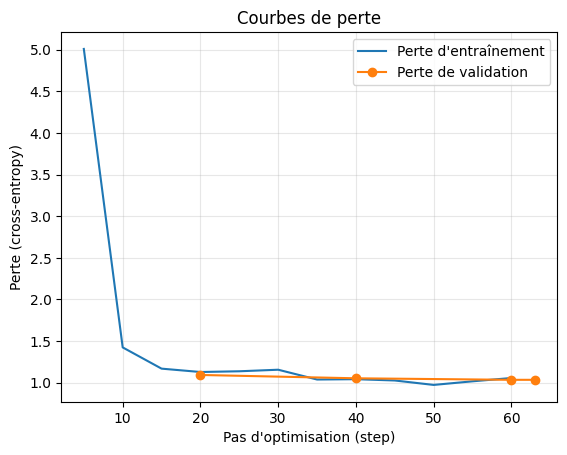

Perte de validation : début = 1.093 | fin = 1.034
Perplexité début : 2.98
Perplexité fin   : 2.81


In [23]:
# VOTRE CODE ICI
log = pd.DataFrame(trainer.state.log_history)

train_log = log.dropna(subset=["loss"])
eval_log = log.dropna(subset=["eval_loss"])

plt.plot(train_log["step"], train_log["loss"], label="Perte d'entraînement")
plt.plot(eval_log["step"], eval_log["eval_loss"], marker="o", label="Perte de validation")
plt.xlabel("Pas d'optimisation (step)")
plt.ylabel("Perte (cross-entropy)")
plt.title("Courbes de perte")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Perte de validation : début = {eval_log['eval_loss'].iloc[0]:.3f} | fin = {eval_log['eval_loss'].iloc[-1]:.3f}")

print(f"Perplexité début : {np.exp(eval_log['eval_loss'].iloc[0]):.2f}")
print(f"Perplexité fin   : {np.exp(eval_log['eval_loss'].iloc[-1]):.2f}")

**Question** : décrire la courbe. La perte de validation remonte-t-elle (sur-apprentissage) ? Que vaut $e^{\text{perte}}$ (la *perplexité*) au début et à la fin, et comment l'interpréter ?

<details>
<summary>💡 Indice</summary>

Calculez `np.exp(...)` sur la première et la dernière valeur de perte. Une perplexité de *k* se lit comme : « le modèle hésite en moyenne entre *k* tokens équiprobables ». Il y a sur-apprentissage quand la perte de validation **remonte** alors que celle d'entraînement continue de baisser.

</details>

✍️ **Votre réponse :**
La coube diminue jusqua l'étape 10 puis stagne , non il y a pas sur apprentissage car on ne la pas entrainer sur les données de test.
On peut voir que la perplexité de diminue le modele hésite de moins en moins au fur et a mesure


## 6. Évaluation

Une erreur classique est de juger un fine-tuning en regardant **quelques** générations. C'est une mauvaise idée car (1) ce n'est pas quantifié et (2) ce qui fonctionne sur trois exemples peut échouer sur des milliers (généralisation). On compare donc le modèle de base et le modèle fine-tuné **sur le même jeu de test, avec la même métrique et les mêmes paramètres de génération**.

**Exercice 10** : générer les résumés du modèle fine-tuné (`ft_summaries`) sur les dialogues d'évaluation, calculer ses scores ROUGE et construire un tableau comparatif avec ceux du modèle de base. Comparer aussi les longueurs moyennes.

<details>
<summary>💡 Indice 1 : générer et évaluer</summary>

Même chose qu'à l'exercice 2, avec `peft_model` (l'adaptateur est actif). Pour une comparaison équitable, utilisez exactement les mêmes dialogues et la même fonction `summarize`.

</details>

<details>
<summary>💡 Indice 2 : le tableau</summary>

`pd.DataFrame({"base": base_scores, "fine-tuné": ft_scores})` place chaque dictionnaire de scores dans une colonne. Ajoutez une colonne `gain` par différence, et réutilisez `mean_words` pour les longueurs.

</details>

In [26]:
# VOTRE CODE ICI
# Générer avec le modèle fine-tuné (l'adaptateur est actif par défaut)
start = time.time()
ft_summaries = summarize(peft_model, eval_dialogues)
print(f"Génération : {time.time() - start:.0f} s")

ft_scores = rouge_scores(ft_summaries, eval_references)

# Tableau comparatif des scores ROUGE
comparaison = pd.DataFrame({"base": base_scores, "fine-tuné": ft_scores})
comparaison["gain"] = comparaison["fine-tuné"] - comparaison["base"]
print(comparaison)

# Longueurs moyennes (en mots)
print(f"\nLongueur moyenne, humain    : {mean_words(eval_references[0]):.1f} mots")
print(f"Longueur moyenne, base      : {mean_words(base_summaries):.1f} mots")
print(f"Longueur moyenne, fine-tuné : {mean_words(ft_summaries):.1f} mots")

Génération : 36 s
ok
            base  fine-tuné   gain
rouge1     25.86      48.91  23.05
rouge2      8.87      23.11  14.24
rougeL     18.85      41.05  22.20
rougeLsum  18.88      41.09  22.21

Longueur moyenne, humain    : 30.0 mots
Longueur moyenne, base      : 76.7 mots
Longueur moyenne, fine-tuné : 26.3 mots


In [38]:
pd.DataFrame({"humain": eval_references, "base": base_summaries, "fine-tuné": ft_summaries}).head(5)

,humain,base,fine-tuné
0,[Ms. Dawson helps #Person1# to write a memo to...,"The conversation involves a manager, Ms. Dawso...",#Person1# asks Ms. Dawson to take a dictation ...
1,[#Person2# arrives late because of traffic jam...,The conversation discusses a person (Person2) ...,#Person2# is stuck in traffic again and #Perso...
2,[#Person1# tells Kate that Masha and Hero get ...,The conversation discusses the surprising news...,Masha and Hero are getting divorced. Masha and...
3,[#Person1# and Brian are at the birthday party...,The conversation is a birthday celebration bet...,#Person1# and Brian have a party. Brian is hap...
4,[#Person1# is surprised at the Olympic Stadium...,The conversation discusses the size and featur...,#Person1# and #Person2# are talking about the ...


**Questions** :
1. Le gain est-il significatif ? Avec 50 exemples seulement, que faudrait-il faire pour s'en assurer ?
2. ROUGE a-t-il augmenté parce que les résumés sont **meilleurs** ou parce qu'ils **ressemblent davantage** aux références ? Comment pourriez-vous mesurer la qualité du contenu (pensez au TP d'initiation) ?

<details>
<summary>💡 Indice</summary>

1. Recalculez ROUGE séparément sur les 25 premiers et les 25 derniers dialogues : de combien les scores varient-ils ? Cherchez aussi « bootstrap confidence interval ».
2. Comparez, dans le tableau ci-dessus, les résumés fine-tunés aux résumés humains : qu'est-ce que le modèle a surtout appris ? Pour juger le contenu, souvenez-vous de la technique d'évaluation par un autre LLM vue dans le TP d'initiation.

</details>

✍️ **Votre réponse :**
Oui le gain est significatif sur le cas de résumé un texte , il faudrait essayer sur une plus grande quantité exemples.
Parceque ressemblent davantage aux références que ce soit en tailles, en utilisant d'autre outils comme BLEU ou demander a un autre llm de l'évaluer


### Oubli catastrophique

Le fine-tuning spécialise le modèle. Vérifions s'il sait encore faire **autre chose** que résumer des dialogues. Grâce à LoRA, il suffit de désactiver l'adaptateur pour retrouver le modèle d'origine.

**Exercice 11** : écrire `chat(model, question)` qui génère une réponse (chat template, `enable_thinking=False`, décodage glouton, 150 nouveaux tokens au plus), puis poser les questions ci-dessous au modèle avec et sans adaptateur.

<details>
<summary>💡 Indice 1 : le prompt</summary>

C'est la même logique que `summarize`, pour un seul texte : pas de lot, donc pas de padding. Le message est `[{"role": "user", "content": question}]`, passé à `apply_chat_template` avec `enable_thinking=False`.

</details>

<details>
<summary>💡 Indice 2 : la génération</summary>

Mêmes paramètres de `generate` que dans `summarize`, avec `max_new_tokens`. Ne décodez que les nouveaux tokens : `output[0, inputs["input_ids"].shape[1]:]`, avec `skip_special_tokens=True`.

</details>

In [29]:
@torch.no_grad()
def chat(model, question, max_new_tokens=150):
    model.eval()
    prompt = tokenizer.apply_chat_template(
        [{"role": "user", "content": question}],
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,
    )
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    output = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        temperature=None,
        top_p=None,
        top_k=None,
    )
    new_tokens = output[0, inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip()


questions = [
    "Explique en deux phrases ce qu'est le fine-tuning d'un LLM.",
    "Write a short dialogue between a waiter and a customer.",
]
for question in questions:
    print(f"### {question}")
    with peft_model.disable_adapter():
        print(f"--- SANS adaptateur :\n{chat(peft_model, question)}")
    print(f"--- AVEC adaptateur :\n{chat(peft_model, question)}\n")

### Explique en deux phrases ce qu'est le fine-tuning d'un LLM.
--- SANS adaptateur :
Le fine-tuning d'un LLM est une étape de mise en forme qui ajuste les paramètres d'un modèle déjà entraîné sur un dataset spécifique, afin d'améliorer sa performance sur un domaine particulier. Cela permet de rendre le modèle plus précis et adapté à des tâches spécifiques comme la classification, la génération de texte ou la rédaction de contenu.
--- AVEC adaptateur :
Le fine-tuning d'un LLM est une technique de fin-tuning pour améliorer la performance d'un modèle.

### Write a short dialogue between a waiter and a customer.
--- SANS adaptateur :
**Waiter:** Good evening, sir. How can I assist you today?

**Customer:** Good evening. I’d like to order a meal. What’s available?

**Waiter:** There’s a classic steak and mushroom risotto, a seafood pasta, and a fresh salad. Would you like a drink as well?

**Customer:** Yes, please. A glass of red wine. What kind?

**Waiter:** We have a selection of reds—c

**Question** : le modèle fine-tuné a-t-il gardé ses capacités générales ? Quels avantages pratiques LoRA offre-t-il face à ce risque ?

<details>
<summary>💡 Indice</summary>

Comparez les réponses avec et sans adaptateur : langue de la réponse, longueur, apparition de `#Person1#`, et la seconde demande produit-elle bien un dialogue ? Pour LoRA, demandez-vous ce que contient l'adaptateur et ce qui arrive aux poids d'origine pendant l'entraînement.

</details>

✍️ **Votre réponse :**
Oui il a gardé ces capacité principal malgré qu'il a tendance a résumé d'avantages ces réponses. LoRA ne modifie qu'un partie des poids donc les autres sont gelés elle ne peut pas perdre son fonctionnement de base juste influencé


## 7. Sauvegarder, recharger, fusionner

`save_pretrained` sur un modèle PEFT ne sauvegarde **que l'adaptateur**.

In [30]:
ADAPTER_DIR = "qwen3-dialogsum-lora/adapter"
peft_model.save_pretrained(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)
for name in sorted(os.listdir(ADAPTER_DIR)):
    print(f"{name:30} {os.path.getsize(os.path.join(ADAPTER_DIR, name)) / 1e6:8.1f} Mo")

README.md                           0.0 Mo
adapter_config.json                 0.0 Mo
adapter_model.safetensors          69.8 Mo
chat_template.jinja                 0.0 Mo
tokenizer.json                     11.4 Mo
tokenizer_config.json               0.0 Mo


Pour réutiliser l'adaptateur (dans une autre session, sur un autre serveur), on charge le modèle de base puis l'adaptateur par-dessus. Libérons d'abord la mémoire du GPU.

**Exercice 12** : supprimer les objets qui occupent le GPU (`trainer`, `peft_model`, `model`) puis appeler `free_memory()`. Recharger ensuite le modèle de base et l'adaptateur avec `PeftModel.from_pretrained`, et vérifier sur 5 dialogues que les résumés sont identiques à `ft_summaries`.

<details>
<summary>💡 Indice 1 : libérer la mémoire</summary>

`del trainer, peft_model, model` supprime les noms Python, mais la mémoire GPU n'est rendue que lorsque plus aucune référence n'existe : c'est le rôle de `free_memory()` (ramasse-miettes + vidage du cache CUDA). Vérifiez avec `gpu_memory()` que la mémoire allouée est retombée près de 0.

</details>

<details>
<summary>💡 Indice 2 : recharger</summary>

Rechargez le modèle de base comme en partie 2 (`AutoModelForCausalLM.from_pretrained`), puis `PeftModel.from_pretrained(base_model, ADAPTER_DIR)`. Le décodage glouton est déterministe : les résumés de `summarize(..., eval_dialogues[:5])` doivent être identiques à `ft_summaries[:5]`.

</details>

In [31]:
from peft import PeftModel

del trainer, peft_model, model
free_memory()
print("Après libération :", gpu_memory())

base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=DTYPE, device_map="cuda")
reloaded = PeftModel.from_pretrained(base_model, ADAPTER_DIR)
print("Après rechargement :", gpu_memory())

reloaded_summaries = summarize(reloaded, eval_dialogues[:5])
print("Résumés identiques :", reloaded_summaries == ft_summaries[:5])
# VOTRE CODE ICI

Après libération : 0.02 Go alloués (pic : 0.02 Go)


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Après rechargement : 3.53 Go alloués (pic : 4.39 Go)
Résumés identiques : True


Pour le **déploiement**, on fusionne souvent l'adaptateur dans les poids ($W' = W + \frac{\alpha}{r} B A$ est calculé une fois pour toutes) : on obtient un modèle standard, sans surcoût de calcul à l'inférence, que l'on peut convertir pour [Ollama](https://ollama.com) ou servir avec [vLLM](https://docs.vllm.ai).

In [32]:
merged = reloaded.merge_and_unload()
print(type(merged).__name__, "| couches LoRA restantes :", sum("lora" in n for n, _ in merged.named_parameters()))
# merged.save_pretrained("qwen3-dialogsum-merged")  # ~3,4 Go : à ne pas faire sur Colab sans raison

Qwen3ForCausalLM | couches LoRA restantes : 0


**Question** : quels sont les avantages et inconvénients de fusionner l'adaptateur, par rapport à le garder séparé ?

<details>
<summary>💡 Indice</summary>

Pensez au déploiement : taille sur disque (affichée plus haut pour l'adaptateur), outils qui ne connaissent pas LoRA (Ollama, llama.cpp), calcul supplémentaire de $BA$ à chaque passage, et cas d'un service qui doit gérer plusieurs tâches avec un même modèle de base.

</details>

✍️ **Votre réponse :**
le fait de le fussioner permet de le donner facilement a Ollama ou autre ,  parcontre c'est une opération qui est difficilement réversible, et cela augmente le poids du model


**Partager son modèle (optionnel)** : avec un compte Hugging Face gratuit et un *token* d'accès en écriture (stocké dans les *Secrets* de Colab, jamais en clair dans le notebook), `reloaded.push_to_hub("votre-nom/qwen3-dialogsum-lora")` publie l'adaptateur sur le Hub. Pensez à rédiger la *model card* : données, hyperparamètres, scores, limites.

In [33]:
del merged, reloaded, base_model
free_memory()

## Mini-projets (au choix)

Choisissez **un** des deux mini-projets. Ils réutilisent les fonctions définies plus haut (`format_example`, `prepare`, `summarize`, `rouge_scores`...). Rédigez une courte analyse de vos résultats.

### Mini-projet A : QLoRA sur un modèle plus gros

**QLoRA** ([Dettmers et al., 2023](https://arxiv.org/abs/2305.14314)) combine LoRA et la quantification : les poids gelés du modèle sont stockés en **4 bits** (format NF4), ce qui divise leur taille par 4 par rapport au 16 bits. Les adaptateurs LoRA restent en haute précision. C'est ce qui permet de fine-tuner des modèles de 7-8 milliards de paramètres sur un GPU gratuit.

Travail demandé :
1. Charger [Qwen3-4B](https://huggingface.co/Qwen/Qwen3-4B) en 4 bits avec un `BitsAndBytesConfig` (`load_in_4bit=True`, `bnb_4bit_quant_type="nf4"`, `bnb_4bit_compute_dtype=DTYPE`, `bnb_4bit_use_double_quant=True`). Mesurer la mémoire GPU occupée et la comparer à ce qu'occuperait le modèle en 16 bits.
2. Préparer le modèle avec `peft.prepare_model_for_kbit_training`, puis l'entraîner avec la même configuration LoRA et les mêmes données que dans le TP (pensez à réduire `per_device_train_batch_size` et à augmenter `gradient_accumulation_steps` d'autant si la mémoire manque).
3. Évaluer le modèle 4B de base et le modèle 4B fine-tuné avec ROUGE, puis construire un tableau comparatif : Qwen3-1.7B base, 1.7B LoRA, 4B base, 4B QLoRA, avec le temps d'entraînement et le pic de mémoire.
4. Analyse : un petit modèle fine-tuné peut-il rivaliser avec un modèle plus gros non fine-tuné ? Quel compromis qualité / coût choisiriez-vous en production ?

### Mini-projet B : combien de données faut-il ?

Le coût d'un fine-tuning est souvent dominé par la **constitution des données** (annotation humaine). Il est donc crucial de savoir combien d'exemples sont vraiment nécessaires.

Travail demandé :
1. Écrire une fonction `finetune(n_train, r=16)` qui charge un modèle frais, l'entraîne sur `n_train` exemples et renvoie ses scores ROUGE. Pour que l'étude tienne dans le temps d'une séance, utilisez [Qwen3-0.6B](https://huggingface.co/Qwen/Qwen3-0.6B) (pensez à libérer la mémoire entre deux entraînements).
2. Entraîner avec 0 (modèle de base), 100, 400 et 1 600 exemples et tracer ROUGE-L en fonction du nombre d'exemples (échelle logarithmique).
3. Avec le meilleur nombre d'exemples, comparer `r=4` et `r=64`.
4. Analyse : à partir de combien d'exemples le gain devient-il marginal ? Le rang a-t-il une influence ? Qu'en concluez-vous pour un projet réel ?

J'ai choisis de faire le Mini Projet B

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

ok
n =     0 -> {'rouge1': np.float64(28.97), 'rouge2': np.float64(9.08), 'rougeL': np.float64(21.61), 'rougeLsum': np.float64(22.51)}



... (29 outputs left out)

Truncating train dataset:   0%|          | 0/1600 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/1600 [00:00<?, ? examples/s]

Step,Training Loss
10,1.792306
20,1.275267
30,1.230603
40,1.191835
50,1.192373
60,1.134012
70,1.158399
80,1.140777
90,1.158834
100,1.118552


n_train=1600, r=16 : entraînement en 5.1 min
ok
n =  1600 -> {'rouge1': np.float64(48.98), 'rouge2': np.float64(22.64), 'rougeL': np.float64(40.53), 'rougeLsum': np.float64(40.55)}



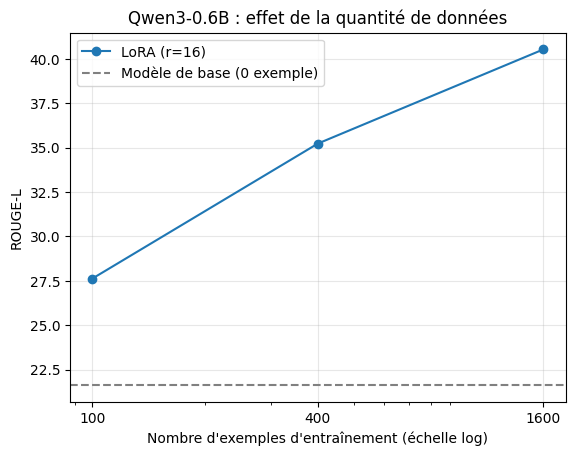

In [34]:
from peft import LoraConfig, get_peft_model
from trl import SFTConfig, SFTTrainer


def finetune(n_train, r=16, model_name="Qwen/Qwen3-0.6B"):
    """Charge un modèle frais, l'entraîne sur n_train exemples (0 = pas d'entraînement) et renvoie ses scores ROUGE."""
    set_seed(42)
    model = AutoModelForCausalLM.from_pretrained(model_name, dtype=DTYPE, device_map="cuda")
    eval_model = model
    trainer = None

    if n_train > 0:
        lora_config = LoraConfig(r=r, lora_alpha=2 * r, lora_dropout=0.05,
                                 target_modules="all-linear", task_type="CAUSAL_LM")
        eval_model = get_peft_model(model, lora_config)
        sft_config = SFTConfig(
            output_dir=f"qwen3-0.6b-lora-{n_train}-r{r}", # le model demandé
            per_device_train_batch_size=4,
            gradient_accumulation_steps=4,
            num_train_epochs=1,
            learning_rate=2e-4,
            lr_scheduler_type="cosine",
            warmup_steps=0.05,
            max_length=MAX_LENGTH,
            gradient_checkpointing=True,
            fp16=not USE_BF16,
            bf16=USE_BF16,
            logging_steps=10,
            eval_strategy="no",      # pour gagner du temps
            save_strategy="no",
            report_to="none",
            seed=42,
        )
        trainer = SFTTrainer(model=eval_model, args=sft_config,
                             train_dataset=prepare("train", n_train),
                             processing_class=tokenizer)
        start = time.time()
        trainer.train()
        print(f"n_train={n_train}, r={r} : entraînement en {(time.time() - start) / 60:.1f} min")

    summaries = summarize(eval_model, eval_dialogues)
    scores = rouge_scores(summaries, eval_references)

    # Libérer la mémoire avant l'entraînement suivant
    del trainer, eval_model, model
    free_memory()
    return scores


# Étude : 0 (modèle de base), 100, 400 et 1 600 exemples
N_LIST = [0, 100, 400, 1600]
results = {}
for n in N_LIST:
    results[n] = finetune(n) # on appelle l'apprentisage pour 0 100 400 1600
    print(f"n = {n:5d} -> {results[n]}\n")

# Graphique ROUGE-L en fonction du nombre d'exemples (échelle log)
xs = [n for n in N_LIST if n > 0]
ys = [results[n]["rougeL"] for n in xs]

plt.plot(xs, ys, marker="o", label="LoRA (r=16)")
plt.axhline(results[0]["rougeL"], color="gray", linestyle="--", label="Modèle de base (0 exemple)")
plt.xscale("log")
plt.xticks(xs, [str(n) for n in xs])
plt.xlabel("Nombre d'exemples d'entraînement (échelle log)")
plt.ylabel("ROUGE-L")
plt.title("Qwen3-0.6B : effet de la quantité de données")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Meilleur nombre d'exemples : 1600


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)


Step,Training Loss
10,2.019840
20,1.364770
30,1.282559
40,1.236641
50,1.227363
60,1.168627
70,1.193665
80,1.173234
90,1.184997
100,1.157828


n_train=1600, r=4 : entraînement en 5.3 min
ok


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)


Step,Training Loss
10,1.647729
20,1.236040
30,1.219670
40,1.180495
50,1.190684
60,1.119516
70,1.143929
80,1.120462
90,1.146240
100,1.103109


n_train=1600, r=64 : entraînement en 5.0 min
ok
        rouge1  rouge2  rougeL  rougeLsum
rang r                                   
4        46.43   20.54   36.84      36.75
16       48.98   22.64   40.53      40.55
64       47.09   19.93   37.54      37.61


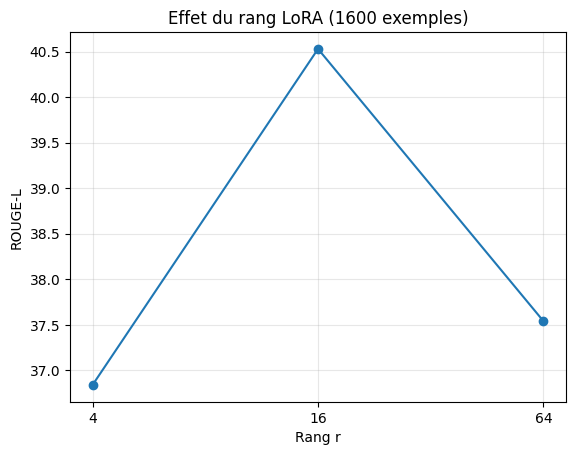

In [39]:
# Meilleur nombre d'exemples d'après l'étude précédente (ROUGE-L maximal)
best_n = max(xs, key=lambda n: results[n]["rougeL"])
print(f"Meilleur nombre d'exemples : {best_n}")

# Comparaison de r=4 et r=64 (r=16 est déjà dans results)
rank_results = {16: results[best_n]}
for r in (4, 64):
    rank_results[r] = finetune(best_n, r=r)

df_rank = pd.DataFrame(rank_results).T.sort_index()
df_rank.index.name = "rang r"
print(df_rank)

plt.plot(df_rank.index, df_rank["rougeL"], marker="o")
plt.xscale("log", base=2)
plt.xticks(df_rank.index, df_rank.index)
plt.xlabel("Rang r")
plt.ylabel("ROUGE-L")
plt.title(f"Effet du rang LoRA ({best_n} exemples)")
plt.grid(alpha=0.3)
plt.show()

On se rend compte que pour double le score de rouge il faut prendre n^2 exemple on peut donc penser que 1600 exemple reste un bon compromis pour notre situation. Oui le rang a une grand influence on se rend que 16 est un bon cela fait drastiquement le score de rouge. Pour un projet il faut donc prendre un range de 16 ou 8 ce qui est recommandé la plus part du temps et d'entrainer sur un jeu de données pas forcément énorme mais seulement 1000 exemple suffise pour avoir une performance suffisante

## Pour aller plus loin

- **[Unsloth](https://github.com/unslothai/unsloth)** : bibliothèque gratuite qui accélère LoRA / QLoRA d'un facteur 2 environ et réduit la mémoire, avec des notebooks Colab prêts à l'emploi pour les modèles récents (Qwen, Llama, Gemma...). Elle s'appuie sur TRL : ce que vous avez appris ici s'y transpose directement.
- **Alignement par préférences** : après le SFT, on peut entraîner le modèle à préférer certaines réponses à d'autres avec **DPO** (`DPOTrainer` de TRL, sur des paires réponse choisie / réponse rejetée), ou par apprentissage par renforcement avec **GRPO** (`GRPOTrainer`), la méthode popularisée par DeepSeek-R1 pour entraîner les modèles de raisonnement.
- **Déploiement local** : après fusion, convertir le modèle au format GGUF avec [llama.cpp](https://github.com/ggml-org/llama.cpp) pour l'exécuter avec Ollama ou LM Studio sur un ordinateur portable.